# Lab 2: Probability and Statistical Measures

**Name:** Arya Patel

## Introduction

This lab explores how probability and statistical measures can help classify
emails and identify unusual prices in a dataset.

In Part A, I will train Gaussian Naive Bayes and Multinomial Naive Bayes
classifiers to identify spam emails. I will compare their performance and
use them to predict labels for test emails.

In Part B, I will compare statistical methods for detecting outliers in
New York City Airbnb prices and produce a cleaned dataset.

# Part A: Spam Email Classification

## Objective

The objective is to classify emails as spam or not spam using their text.

- **Ham (0):** An email labelled as not spam.
- **Spam (1):** An email labelled as spam.

I will compare the two classifiers using accuracy, precision, recall,
F1-score, and confusion matrices.

## 1. Import Libraries

I use pandas to load and inspect the dataset. Scikit-learn provides tools
for splitting the data, converting text into numerical features, training
the classifiers, and evaluating their predictions. Matplotlib will display
the evaluation plots.

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

## 2. Load the Dataset

I load the email dataset into a pandas DataFrame and display the first
five rows to understand its structure.

The text column contains the email content. The label_num column is the
target that the classifiers will predict. The label column provides the
same category in readable form.

In [34]:
spam_df = pd.read_csv("data/Lab2_dataset.csv")

print("Dataset shape:", spam_df.shape)
display(spam_df.head())

Dataset shape: (5171, 4)


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0


## 3. Inspect the Dataset

Before preparing the data, I check its data types, missing values, repeated
email texts, and class counts.

Repeated texts need attention because placing the same email in both
training and testing could make the evaluation overly optimistic.

The class counts also show whether spam and non-spam emails are equally
represented.

In [35]:
spam_df.info()

print("\nMissing values:")
print(spam_df.isna().sum())

print("\nDuplicate email texts:", spam_df.duplicated(subset="text").sum())

print("\nClass distribution:")
display(
    spam_df["label"]
    .value_counts()
    .rename_axis("Class")
    .to_frame("Count")
)

print("\nLabel mapping:")
display(pd.crosstab(spam_df["label"], spam_df["label_num"]))

<class 'pandas.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  5171 non-null   int64
 1   label       5171 non-null   str  
 2   text        5171 non-null   str  
 3   label_num   5171 non-null   int64
dtypes: int64(2), str(2)
memory usage: 161.7 KB

Missing values:
Unnamed: 0    0
label         0
text          0
label_num     0
dtype: int64

Duplicate email texts: 178

Class distribution:


,Count
Class,
ham,3672
spam,1499



Label mapping:


label_num,0,1
label,,
ham,3672,0
spam,0,1499


### Initial Observations

The dataset contains 5,171 emails and has no missing values.
There are 3,672 ham emails and 1,499 spam emails, so the classes
are not equally represented.

I found 178 duplicate email texts. I will remove these before splitting
the dataset to prevent identical emails from appearing in both the
training and testing sets.

The label mapping is consistent: ham is represented by 0 and spam by 1.
The Unnamed: 0 column appears to be a saved index and will be excluded
from model training.

Because ham emails are more common, I will compare precision, recall,
and F1-score alongside accuracy.

## 4. Prepare the Data

I remove duplicate email texts before splitting the dataset so that the
same email cannot appear in both training and testing.

I keep only the text and label_num columns. The email text is the input,
and label_num is the target. The saved index and readable label are not
needed for training.

In [36]:
spam_clean = (
    spam_df[["text", "label_num"]]
    .drop_duplicates(subset="text")
    .reset_index(drop=True)
)

print("Original emails:", len(spam_df))
print("Duplicates removed:", len(spam_df) - len(spam_clean))
print("Remaining emails:", len(spam_clean))

display(spam_clean.head())

Original emails: 5171
Duplicates removed: 178
Remaining emails: 4993


,text,label_num
0,Subject: enron methanol ; meter # : 988291\nth...,0
1,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,"Subject: photoshop , windows , office . cheap ...",1
4,Subject: re : indian springs\nthis deal is to ...,0


## 5. Split the Data into Training and Testing Sets

I use the email text as X and the numerical label as y.

I allocate 80% of the emails for training and 20% for testing.
The training set teaches the models, while the test set evaluates
their predictions on unseen emails.

Using stratify=y keeps approximately the same class proportions in both
sets. Setting random_state=42 makes the split reproducible.

In [37]:
X = spam_clean["text"]
y = spam_clean["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

class_proportions = pd.DataFrame({
    "Training (%)": y_train.value_counts(normalize=True) * 100,
    "Testing (%)": y_test.value_counts(normalize=True) * 100
}).rename(index={0: "Ham", 1: "Spam"})

display(class_proportions.round(2))

print(
    "Identical texts shared between sets:",
    len(set(X_train) & set(X_test))
)

Training emails: 3994
Testing emails: 999


,Training (%),Testing (%)
label_num,,
Ham,70.73,70.67
Spam,29.27,29.33


Identical texts shared between sets: 0


## 6. Convert Email Text into Numerical Features

I use CountVectorizer to represent each email using word counts.
Each column represents a word, and each value shows how many times that
word appears in an email.

For example, if the vocabulary contains "free" and "meeting", the email
"free free meeting" would be represented as [2, 1].

I learn the vocabulary from the training emails only. I then use that
same vocabulary to transform the test emails, preventing information
from the test set from influencing feature preparation.

I limit the vocabulary to the 3,000 most frequent training words to keep
memory usage manageable when using Gaussian Naive Bayes. This is a
practical limit rather than an optimized setting.

In [38]:
vectorizer = CountVectorizer(max_features=3000)

X_train_counts = vectorizer.fit_transform(X_train)
X_test_counts = vectorizer.transform(X_test)

print("Training feature matrix:", X_train_counts.shape)
print("Testing feature matrix:", X_test_counts.shape)
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))

Training feature matrix: (3994, 3000)
Testing feature matrix: (999, 3000)
Vocabulary size: 3000


### Inspect an Example of Word Counts

I display some words found in the first training email and their counts.
The full feature matrix also contains zeros for vocabulary words that
do not appear in that email.

In [39]:
word_counts = pd.Series(
    X_train_counts[0].toarray().ravel(),
    index=vectorizer.get_feature_names_out(),
    name="Count"
)

display(
    word_counts[word_counts > 0]
    .sort_values(ascending=False)
    .head(10)
    .to_frame()
)

,Count
the,11
to,9
deal,8
ua,5
and,4
cleburne,4
we,4
of,3
november,3
from,3


### How Naive Bayes Uses Probability

Naive Bayes uses the features of an email to estimate whether it belongs
to the spam or ham class.

It combines three ideas:

- Prior probability: How common spam and ham are in the training data.
- Likelihood: How likely the email's features are within each class.
- Posterior probability: The estimated class probability after
  considering those features.

The model predicts the class with the higher posterior probability.

The "naive" assumption means that the features are treated as independent
when the class is known. Words are not completely independent in real
emails, but this assumption simplifies the calculations.

Gaussian Naive Bayes models feature values using normal distributions.
Multinomial Naive Bayes models feature counts, which matches the
word-count representation used in this notebook.

## 7. Train the Naive Bayes Classifiers

I train two classifiers using the same training emails and word-count
features.

- Gaussian Naive Bayes assumes that feature values within each class
  follow a normal distribution. Word counts may not fit this assumption
  well, but I include it for the required comparison.
- Multinomial Naive Bayes models word-count features and is commonly
  used for text classification.

Gaussian Naive Bayes requires dense arrays, so I convert its input to
that format. Multinomial Naive Bayes can use the sparse matrices directly.
Both formats contain the same feature values.

The models learn from the training set only. I then use them to predict
whether each test email is ham (0) or spam (1).

In [40]:
# Convert to floating-point dense arrays for Gaussian Naive Bayes.
X_train_dense = X_train_counts.toarray().astype("float32")
X_test_dense = X_test_counts.toarray().astype("float32")

# Train Gaussian Naive Bayes and predict test labels.
gaussian_model = GaussianNB()
gaussian_model.fit(X_train_dense, y_train)

gaussian_predictions = gaussian_model.predict(X_test_dense)

# Train Multinomial Naive Bayes and predict test labels.
multinomial_model = MultinomialNB()
multinomial_model.fit(X_train_counts, y_train)

multinomial_predictions = multinomial_model.predict(X_test_counts)

print("Both classifiers have been trained.")
print("Gaussian predictions:", len(gaussian_predictions))
print("Multinomial predictions:", len(multinomial_predictions))

Both classifiers have been trained.
Gaussian predictions: 999
Multinomial predictions: 999


## 8. Compare Model Performance

I compare both models on the same test set, treating spam (1) as the
positive class.

- Accuracy: The proportion of all emails classified correctly.
- Precision: Of the emails predicted as spam, how many were actually spam?
- Recall: Of the actual spam emails, how many did the model detect?
- F1-score: A measure that balances spam precision and recall.

I use spam F1-score as the main comparison measure because the classes
are unequal and accuracy alone may hide poor spam detection.

In [41]:
predictions = {
    "Gaussian Naive Bayes": gaussian_predictions,
    "Multinomial Naive Bayes": multinomial_predictions
}

results = []

for model_name, y_pred in predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Spam Precision": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Spam Recall": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Spam F1": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        )
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Spam Precision,Spam Recall,Spam F1
Model,,,,
Gaussian Naive Bayes,0.9499,0.8809,0.9590,0.9183
Multinomial Naive Bayes,0.9499,0.8716,0.9727,0.9194


## 9. Examine Classification Results

The classification reports show precision, recall, and F1-score separately
for ham and spam.

The confusion matrices compare actual labels with predicted labels.
Rows represent actual classes, and columns represent predicted classes.

- Actual ham, predicted ham: A non-spam email classified correctly.
- Actual ham, predicted spam: A false positive—a non-spam email flagged as spam.
- Actual spam, predicted ham: A false negative—a spam email missed.
- Actual spam, predicted spam: A spam email classified correctly.

False positives could hide useful emails, while false negatives allow
spam to reach the inbox.

In [42]:
for model_name, y_pred in predictions.items():
    print(model_name)
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Ham", "Spam"],
            digits=4,
            zero_division=0
        )
    )

Gaussian Naive Bayes
              precision    recall  f1-score   support

         Ham     0.9824    0.9462    0.9639       706
        Spam     0.8809    0.9590    0.9183       293

    accuracy                         0.9499       999
   macro avg     0.9316    0.9526    0.9411       999
weighted avg     0.9526    0.9499    0.9505       999

Multinomial Naive Bayes
              precision    recall  f1-score   support

         Ham     0.9881    0.9405    0.9637       706
        Spam     0.8716    0.9727    0.9194       293

    accuracy                         0.9499       999
   macro avg     0.9298    0.9566    0.9415       999
weighted avg     0.9539    0.9499    0.9507       999



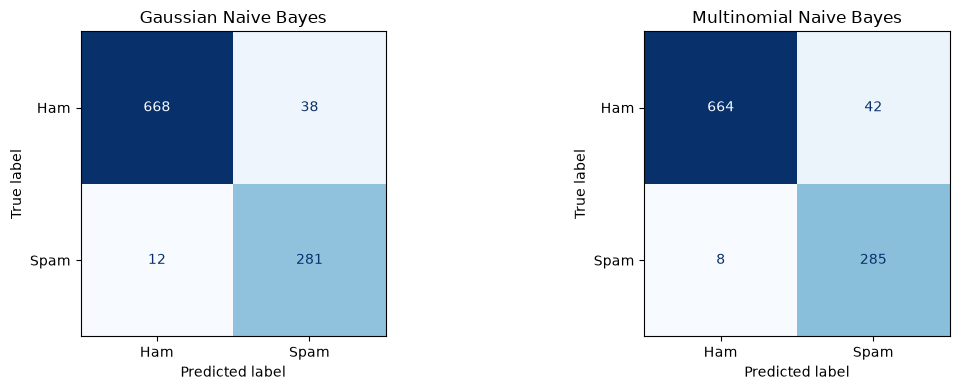

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["Ham", "Spam"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(model_name)

plt.tight_layout()
plt.show()

## 10. Show Predictions on Test Emails

I display ten test emails with their actual labels and the predictions
from both classifiers. These emails were not used to train the models.

I shorten the displayed text to make the table easier to read. The
predictions were generated using the full email text.

In [44]:
label_names = {0: "Ham", 1: "Spam"}

sample_predictions = pd.DataFrame({
    "Email Preview": X_test.iloc[:10].str.slice(0, 120).to_numpy(),
    "Actual": y_test.iloc[:10].to_numpy(),
    "Gaussian": gaussian_predictions[:10],
    "Multinomial": multinomial_predictions[:10]
})

for column in ["Actual", "Gaussian", "Multinomial"]:
    sample_predictions[column] = sample_predictions[column].map(label_names)

display(sample_predictions)

,Email Preview,Actual,Gaussian,Multinomial
0,"Subject: frontrea plant , gas\nwhen : wednesda...",Ham,Spam,Ham
1,Subject: news\nat least two bids seen for enro...,Ham,Ham,Ham
2,"Subject: quailty web solutions , involutory\no...",Spam,Spam,Spam
3,Subject: txu fuels / sds nomination for decemb...,Ham,Ham,Ham
4,Subject: use the links to get more information...,Spam,Spam,Spam
5,Subject: paliourg get the doctors time 4 freee...,Spam,Spam,Spam
6,Subject: registration confirmation from spinne...,Ham,Spam,Spam
7,Subject: re : resume attached\nliz is an mit g...,Ham,Ham,Ham
8,Subject: meter 981594 for jan\nthe meter shows...,Ham,Ham,Ham
9,"Subject: the investor ' s toolbox\nmcintyre ,\...",Spam,Spam,Spam


### Interpretation of Sample Predictions

The first displayed email is labelled as ham. Gaussian Naive Bayes
incorrectly predicts spam, while Multinomial Naive Bayes correctly
predicts ham. This shows that the two models can make different
decisions about the same email.

Both classifiers incorrectly flag the displayed "registration
confirmation" email as spam. This is a false positive and shows
how a useful email could be sent to the spam folder.

These examples help explain individual mistakes. However, I use
the complete test-set results to compare the models because ten
examples do not represent their full performance.

## 11. Part A Conclusion

Both classifiers achieved the same accuracy of approximately 94.99%
on the 999 test emails. However, they made different types of mistakes.

Multinomial Naive Bayes detected more spam emails, missing 8 compared
with 12 for Gaussian Naive Bayes. It also achieved a slightly higher
spam F1-score of 0.9194 compared with 0.9183. Based on my chosen
comparison measure, Multinomial Naive Bayes performed slightly better
on this test set.

Gaussian Naive Bayes had higher spam precision and incorrectly flagged
fewer non-spam emails: 38 compared with 42 for Multinomial Naive Bayes.
This shows a trade-off between detecting more spam and avoiding
incorrect spam warnings.

The difference in F1-score is very small, so there is no strong overall
winner. These results apply to this train/test split and the selected
3,000 word-count features.

## 12. Part A Reflection

This part helped me understand how email text can be used in a
classification model. CountVectorizer converted the emails into word
counts, which allowed the classifiers to work with numerical input.
I also learned why the vocabulary should be learned from the training
emails only, so the test data remains unseen during preparation.

Checking the dataset showed me that having no missing values does not
mean the data is ready for training. There were 178 repeated email
texts that needed to be removed before splitting. Otherwise, identical
emails could appear in both sets and make the results look better
than they really are.

The most useful lesson was that equal accuracy does not mean two
models behave the same way. Multinomial Naive Bayes caught more spam,
while Gaussian Naive Bayes incorrectly flagged fewer non-spam emails.
The confusion matrices helped me connect these numbers to practical
problems, such as missing an important email or receiving unwanted spam.

I would choose Multinomial Naive Bayes for this comparison because it
had slightly higher spam F1-score and recall. However, the results
were very close. A useful next step would be cross-validation to check
whether this small advantage remains across different data splits.

# Part B: Detecting and Removing Airbnb Price Outliers

## Objective

In this part, I will explore nightly prices in the New York City Airbnb
dataset and compare methods for identifying unusually low or high prices.

I will examine the mean, median, standard deviation, percentiles, and
interquartile range. I will also consider room types because an entire
home may reasonably cost more than a shared room.

After comparing the methods, I will select a cleaning rule, explain my
choice, and save the filtered dataset. A price flagged as an outlier is
not necessarily an error; it is unusual according to the selected rule.

## 1. Load the Airbnb Dataset

I load the dataset and display its first five rows to understand its
structure. The price column contains the nightly listing price, which
is the focus of this analysis.

In [45]:
airbnb_df = pd.read_csv("data/AB_NYC_2019.csv")

print("Dataset shape:", airbnb_df.shape)
display(airbnb_df.head())

Dataset shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## 2. Inspect Data Quality

I check the column types, missing values, duplicate rows, and room types.

I also check for missing, non-numeric, zero, or negative prices. For this
analysis, a valid nightly price must be a finite number greater than zero.

Missing information in unrelated columns, such as review dates, does not
automatically make a listing unsuitable for price analysis. I will avoid
removing rows just because those unrelated values are missing.

In [46]:
airbnb_df.info()

print("\nMissing values:")
print(airbnb_df.isna().sum())

print("\nDuplicate rows:", airbnb_df.duplicated().sum())

print("\nRoom types:")
print(airbnb_df["room_type"].value_counts(dropna=False))

price_numeric = pd.to_numeric(airbnb_df["price"], errors="coerce")

print("\nMissing or non-numeric prices:", price_numeric.isna().sum())
print("Zero prices:", price_numeric.eq(0).sum())
print("Negative prices:", price_numeric.lt(0).sum())
print("Infinite prices:", price_numeric.isin([float("inf"), -float("inf")]).sum())

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

## 3. Examine Initial Price Statistics

I calculate summary statistics before removing outliers. The mean and
median describe typical prices, while the standard deviation and
percentiles help describe their spread.

Comparing these values will help me understand whether a small number
of expensive listings pull the mean above the median.

In [47]:
display(
    price_numeric.describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).round(2).to_frame("Nightly Price")
)

display(
    airbnb_df.assign(price=price_numeric)
    .groupby("room_type")["price"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

,Nightly Price
count,48895.00
mean,152.72
std,240.15
min,0.00
1%,30.00
25%,69.00
50%,106.00
75%,175.00
95%,355.00
99%,799.00


,count,mean,median,std,min,max
room_type,,,,,,
Entire home/apt,25409,211.79,160.0,284.04,0,10000
Private room,22326,89.78,70.0,160.21,0,10000
Shared room,1160,70.13,45.0,101.73,0,1800


## 4. Prepare Valid Price Data

For this analysis, I keep listings with a finite nightly price greater
than zero. A zero price cannot represent a usable nightly rental price,
so I exclude it from the price analysis.

I also remove exact duplicate rows. Missing values in unrelated columns
are left unchanged because they do not prevent price analysis.

I keep the original dataset and create a separate working copy. All
outlier detection methods will use this same working dataset so their
results can be compared fairly.

In [48]:
valid_price_mask = (
    price_numeric.notna()
    & price_numeric.gt(0)
    & ~price_numeric.isin([float("inf"), -float("inf")])
)

airbnb_valid = airbnb_df.loc[valid_price_mask].copy()
airbnb_valid["price"] = price_numeric.loc[valid_price_mask]

duplicates_removed = airbnb_valid.duplicated().sum()
airbnb_valid = airbnb_valid.drop_duplicates().copy()

print("Original listings:", len(airbnb_df))
print("Invalid prices removed:", (~valid_price_mask).sum())
print("Exact duplicates removed:", duplicates_removed)
print("Listings available for outlier analysis:", len(airbnb_valid))

Original listings: 48895
Invalid prices removed: 11
Exact duplicates removed: 0
Listings available for outlier analysis: 48884


## 5. Visualize Prices Before Outlier Removal

I use a histogram to show how nightly prices are distributed and a
boxplot to highlight potentially unusual prices.

I also show prices on a logarithmic horizontal scale. This makes it
easier to see the main distribution when prices cover a wide range.
The logarithmic scale only changes the display; it does not change
the dataset or remove any listings.

Points beyond a boxplot's whiskers are potential outliers under the
IQR rule, rather than confirmed data errors.

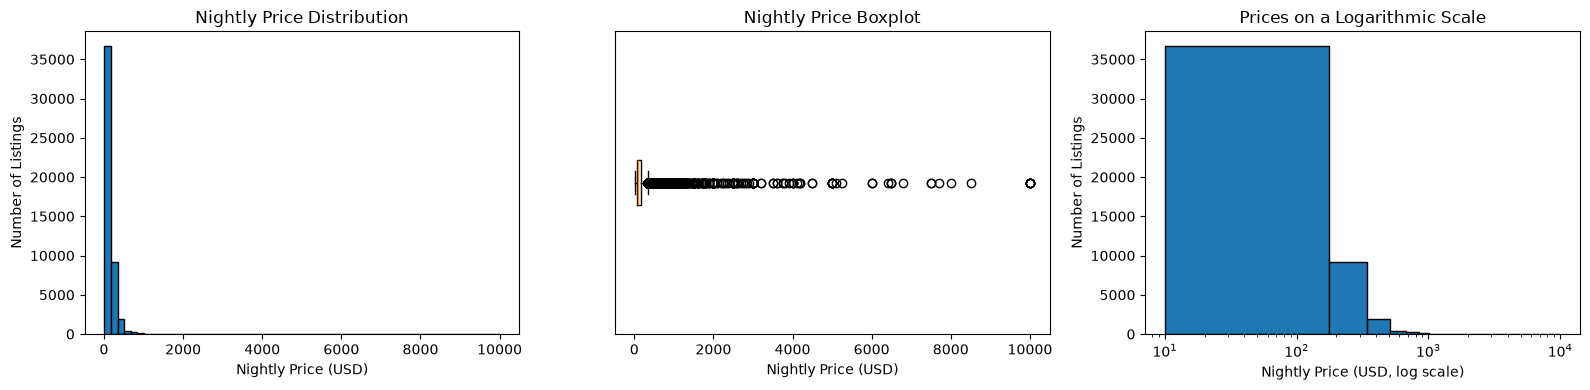

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

airbnb_valid["price"].plot.hist(
    bins=60,
    ax=axes[0],
    edgecolor="black"
)
axes[0].set_title("Nightly Price Distribution")
axes[0].set_xlabel("Nightly Price (USD)")
axes[0].set_ylabel("Number of Listings")

axes[1].boxplot(
    airbnb_valid["price"],
    orientation="horizontal"
)
axes[1].set_title("Nightly Price Boxplot")
axes[1].set_xlabel("Nightly Price (USD)")
axes[1].set_yticks([])

airbnb_valid["price"].plot.hist(
    bins=60,
    logx=True,
    ax=axes[2],
    edgecolor="black"
)
axes[2].set_title("Prices on a Logarithmic Scale")
axes[2].set_xlabel("Nightly Price (USD, log scale)")
axes[2].set_ylabel("Number of Listings")

plt.tight_layout()
plt.show()

### Compare Prices Across Room Types

I compare room types separately because their typical prices may differ.
A price that is unusual for a shared room may be reasonable for an
entire home. This comparison helps me assess whether one price threshold
for all listings would be appropriate.

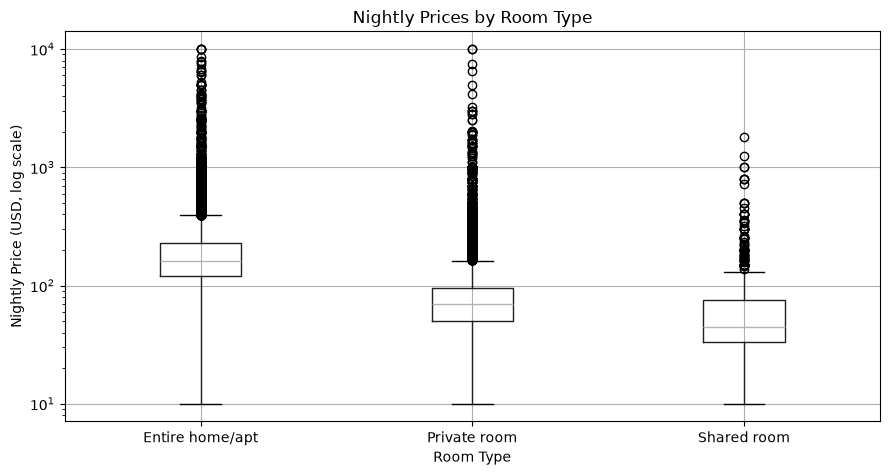

In [50]:
airbnb_valid.boxplot(
    column="price",
    by="room_type",
    figsize=(9, 5)
)

plt.yscale("log")
plt.title("Nightly Prices by Room Type")
plt.suptitle("")
plt.xlabel("Room Type")
plt.ylabel("Nightly Price (USD, log scale)")
plt.tight_layout()
plt.show()

## 6. Compare Outlier Detection Methods

I compare four methods using the same valid-price dataset:

1. Mean ± 3 standard deviations: Flags prices far from the mean.
   Extreme prices can influence both the mean and standard deviation.

2. Median and MAD: MAD is the median absolute distance from the median.
   I flag prices whose absolute modified Z-score exceeds 3.5.
   This method is less influenced by extreme values.

3. Percentiles: Keeps prices between the 1st and 99th percentiles.
   This trims the tails but does not prove that excluded prices are errors.

4. IQR: Keeps prices between Q1 − 1.5 × IQR and Q3 + 1.5 × IQR,
   where IQR = Q3 − Q1.

These are alternative rules. I apply each one independently rather than
removing rows repeatedly using all four methods.

For this first comparison, I calculate thresholds across all room types.
I will also examine thresholds within room types before selecting the
final cleaning rule.

### Understanding the Median/MAD Rule

MAD is the median of the absolute distances between each price and
the median price.

I use the modified Z-score:

Modified Z-score = 0.6745 × (price − median) / MAD

The constant 0.6745 is a conventional scaling factor that makes this
score comparable to a standard Z-score for normally distributed data.
I flag prices whose absolute modified Z-score exceeds 3.5.

My code expresses this same rule as a price interval:

Lower bound = median − (3.5 × MAD / 0.6745)
Upper bound = median + (3.5 × MAD / 0.6745)

This method is less affected by extreme prices than the mean and
standard deviation. It does not require me to claim that Airbnb
prices follow a normal distribution.

In [51]:
prices = airbnb_valid["price"]

# Method 1: Mean ± 3 standard deviations
price_mean = prices.mean()
price_std = prices.std()

mean_lower = price_mean - 3 * price_std
mean_upper = price_mean + 3 * price_std

# Method 2: Median and median absolute deviation (MAD)
price_median = prices.median()
price_mad = (prices - price_median).abs().median()

if price_mad == 0:
    raise ValueError("MAD is zero; modified Z-scores cannot be calculated.")

mad_distance = 3.5 * price_mad / 0.6745
mad_lower = price_median - mad_distance
mad_upper = price_median + mad_distance

# Method 3: 1st–99th percentiles
percentile_lower = prices.quantile(0.01)
percentile_upper = prices.quantile(0.99)

# Method 4: Interquartile range
q1 = prices.quantile(0.25)
q3 = prices.quantile(0.75)
price_iqr = q3 - q1

iqr_lower = q1 - 1.5 * price_iqr
iqr_upper = q3 + 1.5 * price_iqr

thresholds = {
    "Mean ± 3 SD": (mean_lower, mean_upper),
    "Median / MAD": (mad_lower, mad_upper),
    "1st–99th Percentiles": (percentile_lower, percentile_upper),
    "IQR": (iqr_lower, iqr_upper)
}

display(
    pd.DataFrame.from_dict(
        thresholds,
        orient="index",
        columns=["Lower Bound", "Upper Bound"]
    ).round(2)
)

,Lower Bound,Upper Bound
Mean ± 3 SD,-567.76,873.27
Median / MAD,-132.70,344.70
1st–99th Percentiles,30.00,799.00
IQR,-90.00,334.00


## 7. Compare the Effects of Each Method

For each method, I count the listings retained and removed, then calculate
the remaining mean, median, and price range.

A method that removes more listings is not automatically better.
I need to consider whether it also excludes reasonable prices.

I store each filtered dataset separately so the original working data
remains available.

In [52]:
filtered_datasets = {}
comparison_rows = []

for method, (lower, upper) in thresholds.items():
    keep_mask = prices.between(lower, upper, inclusive="both")
    filtered = airbnb_valid.loc[keep_mask].copy()

    filtered_datasets[method] = filtered

    comparison_rows.append({
        "Method": method,
        "Retained": len(filtered),
        "Removed": len(airbnb_valid) - len(filtered),
        "Removed (%)": (~keep_mask).mean() * 100,
        "Mean Price": filtered["price"].mean(),
        "Median Price": filtered["price"].median(),
        "Min Price": filtered["price"].min(),
        "Max Price": filtered["price"].max()
    })

outlier_comparison = pd.DataFrame(comparison_rows).set_index("Method")

display(outlier_comparison.round(2))

,Retained,Removed,Removed (%),Mean Price,Median Price,Min Price,Max Price
Method,,,,,,,
Mean ± 3 SD,48496,388,0.79,138.78,105.0,10,860
Median / MAD,45968,2916,5.97,120.27,100.0,10,344
1st–99th Percentiles,48017,867,1.77,138.50,105.0,30,799
IQR,45912,2972,6.08,120.00,100.0,10,334


## 8. Detect Outliers Within Each Room Type

The earlier methods used one set of price thresholds for all listings.
However, different room types may have different typical prices.

I now calculate the IQR boundaries separately for each room type.
This compares a listing with others in the same accommodation category.

I use the standard boundaries:
- Lower bound = Q1 − 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR

These boundaries identify statistically unusual prices. They do not
prove that an expensive listing is incorrect. Location and other
property characteristics can also affect prices.

In [53]:
room_thresholds = (
    airbnb_valid.groupby("room_type")["price"]
    .agg(
        Q1=lambda values: values.quantile(0.25),
        Q3=lambda values: values.quantile(0.75)
    )
)

room_thresholds["IQR"] = (
    room_thresholds["Q3"] - room_thresholds["Q1"]
)

room_thresholds["Lower Bound"] = (
    room_thresholds["Q1"] - 1.5 * room_thresholds["IQR"]
)

room_thresholds["Upper Bound"] = (
    room_thresholds["Q3"] + 1.5 * room_thresholds["IQR"]
)

display(room_thresholds.round(2))

,Q1,Q3,IQR,Lower Bound,Upper Bound
room_type,,,,,
Entire home/apt,120.0,229.0,109.0,-43.5,392.5
Private room,50.0,95.0,45.0,-17.5,162.5
Shared room,33.0,75.0,42.0,-30.0,138.0


## 9. Create a Dataset Using Room-Type IQR Boundaries

I match each listing to the boundaries calculated for its room type,
then keep prices within those boundaries.

I calculate the boundaries once from the valid-price dataset and keep
them fixed. This makes the cleaning rule reproducible and avoids
repeatedly removing listings as the quartiles change.

I retain the excluded listings separately so they can be reviewed.

In [54]:
listing_lower = airbnb_valid["room_type"].map(
    room_thresholds["Lower Bound"]
)

listing_upper = airbnb_valid["room_type"].map(
    room_thresholds["Upper Bound"]
)

# Every listing must have a room type with calculated boundaries.
assert listing_lower.notna().all() and listing_upper.notna().all(), (
    "Some listings have missing or unrecognized room types."
)

room_iqr_mask = airbnb_valid["price"].between(
    listing_lower,
    listing_upper,
    inclusive="both"
)

airbnb_room_iqr = airbnb_valid.loc[room_iqr_mask].copy()
airbnb_room_outliers = airbnb_valid.loc[~room_iqr_mask].copy()

print("Valid-price listings:", len(airbnb_valid))
print("Retained listings:", len(airbnb_room_iqr))
print("Flagged listings:", len(airbnb_room_outliers))
print(f"Flagged percentage: {(~room_iqr_mask).mean() * 100:.2f}%")

Valid-price listings: 48884
Retained listings: 45640
Flagged listings: 3244
Flagged percentage: 6.64%


In [55]:
room_comparison = pd.DataFrame({
    "Before": airbnb_valid.groupby("room_type").size(),
    "Retained": airbnb_room_iqr.groupby("room_type").size()
}).fillna(0).astype(int)

room_comparison["Removed"] = (
    room_comparison["Before"] - room_comparison["Retained"]
)

room_comparison["Removed (%)"] = (
    room_comparison["Removed"] / room_comparison["Before"] * 100
)

display(room_comparison.round(2))

,Before,Retained,Removed,Removed (%)
room_type,,,,
Entire home/apt,25407,23536,1871,7.36
Private room,22319,21029,1290,5.78
Shared room,1158,1075,83,7.17


In [56]:
outlier_comparison.loc["IQR by Room Type"] = {
    "Retained": len(airbnb_room_iqr),
    "Removed": len(airbnb_room_outliers),
    "Removed (%)": (~room_iqr_mask).mean() * 100,
    "Mean Price": airbnb_room_iqr["price"].mean(),
    "Median Price": airbnb_room_iqr["price"].median(),
    "Min Price": airbnb_room_iqr["price"].min(),
    "Max Price": airbnb_room_iqr["price"].max()
}

display(outlier_comparison.round(2))

,Retained,Removed,Removed (%),Mean Price,Median Price,Min Price,Max Price
Method,,,,,,,
Mean ± 3 SD,48496,388,0.79,138.78,105.0,10,860
Median / MAD,45968,2916,5.97,120.27,100.0,10,344
1st–99th Percentiles,48017,867,1.77,138.50,105.0,30,799
IQR,45912,2972,6.08,120.00,100.0,10,334
IQR by Room Type,45640,3244,6.64,121.81,100.0,10,392


## 10. Validate the Final Price-Filtered Dataset

I select IQR by room type as my final cleaning rule because different
accommodation types can have different price ranges.

I check that every retained listing has a finite, positive price within
its room type's original IQR boundaries.

These boundaries remain fixed after filtering. Recalculating quartiles
on the filtered data could produce different boundaries and flag more
listings. Therefore, "no remaining outliers" means no prices fall outside
the original boundaries used for this cleaning step.

This dataset is filtered for price analysis. Missing values in unrelated
columns may still remain.

In [57]:
airbnb_clean = airbnb_room_iqr.copy()

clean_lower = airbnb_clean["room_type"].map(
    room_thresholds["Lower Bound"]
)
clean_upper = airbnb_clean["room_type"].map(
    room_thresholds["Upper Bound"]
)

valid_clean_prices = (
    airbnb_clean["price"].notna()
    & airbnb_clean["price"].gt(0)
    & ~airbnb_clean["price"].isin([float("inf"), -float("inf")])
)

within_original_bounds = airbnb_clean["price"].between(
    clean_lower,
    clean_upper,
    inclusive="both"
)

assert not airbnb_clean.empty, "The filtered dataset is empty."
assert valid_clean_prices.all(), "Invalid prices remain."
assert within_original_bounds.all(), "Prices outside the boundaries remain."
assert not airbnb_clean.duplicated().any(), "Exact duplicate rows remain."

print("Validation passed.")
print("Final listings:", len(airbnb_clean))
print("Prices outside original room-type boundaries:",
      (~within_original_bounds).sum())

Validation passed.
Final listings: 45640
Prices outside original room-type boundaries: 0


## 11. Compare Prices Before and After Filtering

I compare summary statistics and price distributions before and after
applying the selected rule.

For this comparison, "before" means the dataset after invalid prices
and exact duplicates were removed, but before statistical outlier
filtering.

The histograms use the same bins and logarithmic price scale so the
distributions can be compared consistently.

In [58]:
price_summary = pd.DataFrame({
    "Before Outlier Filtering": airbnb_valid["price"].describe(),
    "After Room-Type IQR": airbnb_clean["price"].describe()
})

display(price_summary.round(2))

,Before Outlier Filtering,After Room-Type IQR
count,48884.00,45640.00
mean,152.76,121.81
std,240.17,73.23
min,10.00,10.00
25%,69.00,65.00
50%,106.00,100.00
75%,175.00,156.00
max,10000.00,392.00


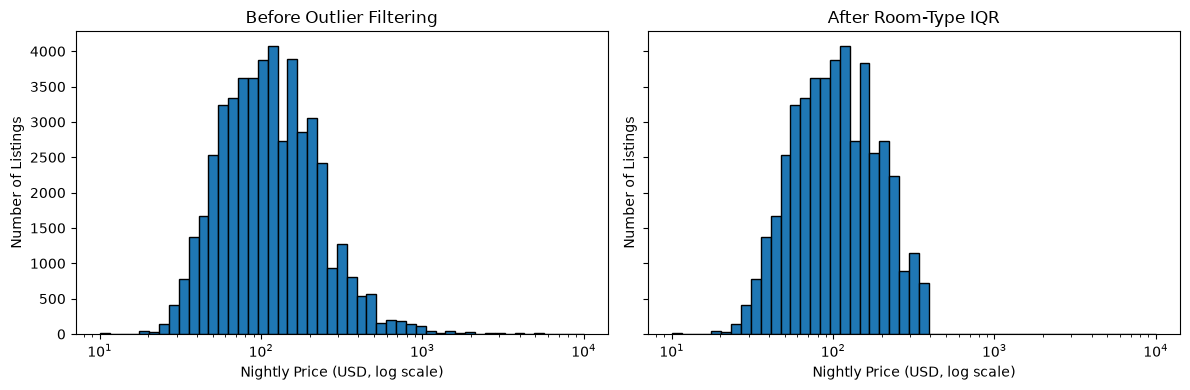

In [59]:
import numpy as np

price_bins = np.geomspace(
    airbnb_valid["price"].min(),
    airbnb_valid["price"].max(),
    50
)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4), sharex=True, sharey=True
)

datasets_to_plot = [
    ("Before Outlier Filtering", airbnb_valid),
    ("After Room-Type IQR", airbnb_clean)
]

for ax, (title, dataset) in zip(axes, datasets_to_plot):
    ax.hist(
        dataset["price"],
        bins=price_bins,
        edgecolor="black"
    )
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("Nightly Price (USD, log scale)")
    ax.set_ylabel("Number of Listings")

plt.tight_layout()
plt.show()

## 12. Save the Results

I save the final price-filtered dataset as a new CSV, preserving the
original dataset.

I also save the excluded price outliers, the room-type boundaries,
and the method comparison table. These files document which rule
was applied and allow the excluded listings to be reviewed.

In [60]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

airbnb_clean.to_csv(
    output_dir / "AB_NYC_2019_price_cleaned.csv",
    index=False
)

airbnb_room_outliers.to_csv(
    output_dir / "AB_NYC_2019_price_outliers.csv",
    index=False
)

room_thresholds.to_csv(
    output_dir / "room_type_iqr_boundaries.csv"
)

outlier_comparison.to_csv(
    output_dir / "outlier_method_comparison.csv"
)

print("Results saved in the outputs folder.")

Results saved in the outputs folder.


## 13. Part B Conclusion

The original dataset contained 48,895 listings. I excluded 11 listings
with zero prices, leaving 48,884 listings for outlier analysis.

The methods produced different results. Mean ± 3 standard deviations
removed 388 listings, median/MAD removed 2,916, percentiles removed 867,
and the overall IQR method removed 2,972. This shows that the definition
of an outlier depends on the rule being used.

The mean-based upper boundary was approximately $873.27, compared with
$334 for the overall IQR method. The extreme prices increased the mean
and standard deviation, making the mean-based rule more permissive.
The percentile method provided explicit cutoffs, but it could also
exclude valid low-cost listings.

I selected IQR by room type because entire homes, private rooms, and
shared rooms have different price distributions. Their upper boundaries
were $392.50, $162.50, and $138 respectively. For example, a $200 listing
would be retained for an entire home but flagged for a private room.

The selected method excluded 3,244 listings, or 6.64% of the valid-price
dataset, and retained 45,640 listings. The mean price decreased from
$152.76 to $121.81, while the median decreased from $106 to $100.

Validation confirmed that all retained prices were positive and within
their original room-type IQR boundaries. The final dataset was saved
as AB_NYC_2019_price_cleaned.csv.

The excluded listings are statistically unusual under this rule, but
they are not necessarily incorrect. Location, property size, and luxury
features could explain some high prices.

## 14. Part B Reflection

This part helped me understand why looking only at the average price
can be misleading. Before filtering, the mean was $152.76 while the
median was $106. The expensive listings pulled the mean upward, so
comparing both measures gave me a clearer understanding of typical
prices.

I also learned that different outlier methods do not give the same
answer. The mean-based method removed far fewer listings than IQR
or median/MAD. This helped me understand why I should explain my
choice instead of assuming that any statistical method is suitable.

Comparing room types was useful because a price can be reasonable
for one category and unusual for another. I chose room-type IQR
because it considered this difference. However, it still does not
account for every factor, such as location or property size.

My main takeaway is that cleaning data requires judgment. Removing
more rows does not automatically create a better dataset. I kept
the original data and saved the excluded listings separately so
the decisions could be reviewed later.

# References

## Assignment and Datasets

- [Lab 2 Assignment Instructions](https://github.com/aaiml/CSCN8000-lab-submissions/blob/main/practical_labs/Lab2.md)
- [Spam Email Dataset](https://github.com/aaiml/CSCN8000-lab-submissions/blob/main/practical_labs/Lab2_dataset.csv)
- [New York City Airbnb Dataset](https://github.com/aaiml/CSCN8000-lab-submissions/blob/main/practical_labs/AB_NYC_2019.csv)

## Supporting Documentation

- [Scikit-learn: Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html)
- [Scikit-learn: CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)
- [SciPy: Median Absolute Deviation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.median_abs_deviation.html)
- [GitHub Pages Quickstart](https://docs.github.com/en/pages/quickstart)